# Issue #3: SOFR Futures Pricing Framework

**Goal.** Given an *assumed* path of daily SOFR rates, compute the *theoretical* price of
One-Month (SR1) and Three-Month (SR3) SOFR futures.

This is the "forward" direction of the project. Issue #4 will run it in reverse: it will search
for the FOMC rate moves whose theoretical prices best match the prices seen in the market.

**What this notebook shows**

1. How a SOFR fixing path turns into daily rates (weekends carry Friday's rate).
2. SR1 pricing with hand-checked examples.
3. SR3 pricing, and why compounding makes it differ from SR1.
4. Pricing a whole strip of contracts from one rate path.
5. How sensitive each contract is to the timing of a rate move.
6. The safety checks, and the unit tests.

## 1. Conventions

* Rates are in **percent** (`4.25` means 4.25%). Prices are index points. Always: `price = 100 - rate`.
* A **fixing path** is a pandas Series: the index holds business days, the values hold SOFR in percent.
  A fixing stays in force until the next fixing, so a Friday fixing also covers Saturday and Sunday.
* **SR1** settles on the average SOFR over a calendar month:
  $$R_{SR1} = \frac{1}{D}\sum_{\text{days}} r_{\text{day}}$$
* **SR3** settles on SOFR compounded over its reference quarter (actual/360):
  $$A = \prod_k \left(1 + \frac{d_k}{360}\cdot\frac{r_k}{100}\right), \qquad R_{SR3} = (A-1)\cdot\frac{360}{D}\cdot 100$$
  where $d_k$ is how many calendar days fixing $k$ is in force during the period.
* Reference periods include both the first and the last day.

In [1]:
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

# The notebook lives in <repo>/notebooks, so the repository root is one level up.
REPO_ROOT = os.path.abspath("..")
sys.path.insert(0, REPO_ROOT)

from sofr_pricing import (
    contract_price,
    fixing_dates,
    get_rate_blocks,
    price_contracts,
    sr1_price,
    sr1_rate,
    sr3_price,
    sr3_rate,
)

pd.options.display.float_format = "{:.4f}".format

### A small helper for this demo

The real tool that builds rate paths from FOMC meetings belongs to **Issue #4**.
For this demo we only need a simple path: one flat rate, plus optional rate changes.

In [2]:
def make_path(start, end, rate, moves=None):
    # Build a SOFR fixing path: `rate` everywhere, plus optional rate changes.
    #
    # `moves` is a dictionary {effective_date: change_in_percent}.
    # Example: {"2024-06-20": -0.25} means a 25 bp cut starting on June 20.
    dates = fixing_dates(start, end)
    path = pd.Series(float(rate), index=dates)

    if moves is not None:
        for effective_date, change in moves.items():
            path[path.index >= pd.Timestamp(effective_date)] += change

    return path

## 2. From fixings to days: the weekend rule

`get_rate_blocks` cuts a period into blocks of days that share one fixing.
Here is one week, where every fixing has a different rate so we can see which one is used when.

In [3]:
# Wed Jun 19 to Tue Jun 25, 2024: five fixings with different rates.
dates = fixing_dates("2024-06-19", "2024-06-25")
week = pd.Series([1.0, 2.0, 3.0, 4.0, 5.0], index=dates)

blocks = get_rate_blocks(week, "2024-06-19", "2024-06-25")

for fixing_date, (rate, days) in zip(dates, blocks):
    print(f"{fixing_date.strftime('%a %Y-%m-%d')}: rate {rate} applies for {days} day(s)")

Wed 2024-06-19: rate 1.0 applies for 1 day(s)
Thu 2024-06-20: rate 2.0 applies for 1 day(s)
Fri 2024-06-21: rate 3.0 applies for 3 day(s)
Mon 2024-06-24: rate 4.0 applies for 1 day(s)
Tue 2024-06-25: rate 5.0 applies for 1 day(s)


Friday's rate applies for **3 days** (Friday, Saturday, Sunday). This is why a rate change that takes
effect on a Monday only starts to count on Monday.

## 3. SR1: the average over the month

**Example.** June 2024 has 30 days. The Fed cuts by 25 bp and the new rate starts on Thursday June 20.

* June 1 to 19: 19 days at 5.00%
* June 20 to 30: 11 days at 4.75%

$$R_{SR1} = \frac{19 \times 5.00 + 11 \times 4.75}{30}$$

In [4]:
june_path = make_path("2024-05-01", "2024-07-31", 5.00, {"2024-06-20": -0.25})

model_rate = sr1_rate(june_path, "2024-06-01", "2024-06-30")
hand_rate = (19 * 5.00 + 11 * 4.75) / 30

print(f"hand calculation : {hand_rate:.6f} %")
print(f"our function     : {model_rate:.6f} %")
print(f"SR1 futures price: {sr1_price(june_path, '2024-06-01', '2024-06-30'):.6f}")

hand calculation : 4.908333 %
our function     : 4.908333 %
SR1 futures price: 95.091667


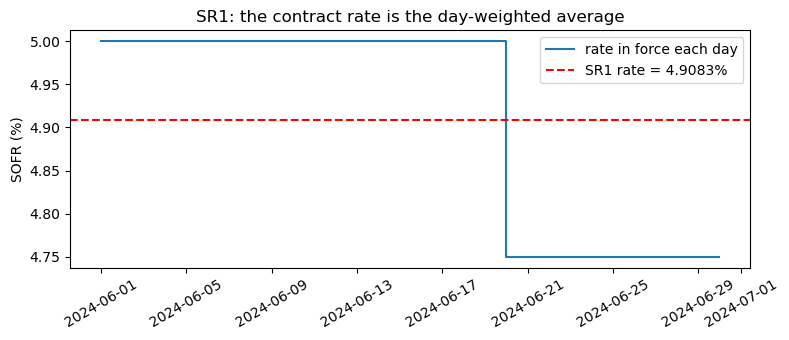

In [5]:
# Picture: the daily rate in force during June, and its average.
days = pd.date_range("2024-06-01", "2024-06-30", freq="D")
daily_rate = june_path.reindex(days, method="ffill")  # weekends reuse Friday

plt.figure(figsize=(8, 3.5))
plt.step(days, daily_rate, where="post", label="rate in force each day")
plt.axhline(model_rate, color="red", linestyle="--", label=f"SR1 rate = {model_rate:.4f}%")
plt.title("SR1: the contract rate is the day-weighted average")
plt.ylabel("SOFR (%)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Weekend check.** Now the cut starts on **Monday** June 17. Saturday and Sunday (June 15-16) still use
Friday's old rate: 16 days at 5.00% and 14 days at 4.75%.

In [6]:
monday_path = make_path("2024-05-01", "2024-07-31", 5.00, {"2024-06-17": -0.25})

model_rate = sr1_rate(monday_path, "2024-06-01", "2024-06-30")
hand_rate = (16 * 5.00 + 14 * 4.75) / 30

print(f"hand calculation: {hand_rate:.6f} %")
print(f"our function    : {model_rate:.6f} %")

hand calculation: 4.883333 %
our function    : 4.883333 %


## 4. SR3: compounding over the quarter

**Example.** SR3 December 2024 runs from Wed 2024-12-18 to Tue 2025-03-18, which is 91 days, or 13 whole weeks.
With a flat rate and no holidays, each Wed-to-Tue week has these fixings:

| Fixing | Days in force |
|---|---|
| Wed | 1 |
| Thu | 1 |
| Fri | 3 (Fri + Sat + Sun) |
| Mon | 1 |
| Tue | 1 |

With $x = r/36000$, one week multiplies money by $(1+x)^4(1+3x)$, so $A = \left[(1+x)^4(1+3x)\right]^{13}$.

In [7]:
rate = 5.00
x = rate / 36000

growth = ((1 + x) ** 4 * (1 + 3 * x)) ** 13
hand_rate = (growth - 1) * 360 / 91 * 100

flat_path = make_path("2024-12-01", "2025-03-31", rate)
model_rate = sr3_rate(flat_path, "2024-12-18", "2025-03-18")

print(f"hand calculation (closed form): {hand_rate:.8f} %")
print(f"our function                  : {model_rate:.8f} %")

hand calculation (closed form): 5.03107786 %
our function                  : 5.03107786 %


### Compounding versus a plain average

With the **same** 5.00% rate every day, SR1-style averaging gives exactly 5.00%.
SR3 gives a little more, because interest earns interest.

In [8]:
simple_average = sr1_rate(flat_path, "2024-12-18", "2025-03-18")
compounded = sr3_rate(flat_path, "2024-12-18", "2025-03-18")

print(f"plain average : {simple_average:.4f} %")
print(f"compounded    : {compounded:.4f} %")
print(f"difference    : {(compounded - simple_average) * 100:.2f} basis points")

plain average : 5.0000 %
compounded    : 5.0311 %
difference    : 3.11 basis points


This gap of about 3 bp is **not** a market view. It is built into the contract definition,
so Issue #4 must price SR1 and SR3 with their own formulas and never treat them as interchangeable.

## 5. Pricing a whole strip of contracts

`price_contracts` takes one rate path and a table of contracts, and returns one theoretical price per contract.
This is the step that Issue #4 will repeat many times while searching for the best path.

**Scenario.** SOFR is 4.33% and the Fed cuts 25 bp at its September 2025 meeting
(announced Wednesday Sep 17, effective Thursday Sep 18).

The reference periods below follow the same convention as the data branch (`sofr_data.contracts`).

In [9]:
rows = []

# SR1: one contract per calendar month of 2025.
for month in range(1, 13):
    first_day = pd.Timestamp(year=2025, month=month, day=1)
    last_day = first_day + pd.offsets.MonthEnd(0)
    rows.append({"contract": f"SR1 2025-{month:02d}", "root": "SR1",
                 "reference_start": first_day, "reference_end": last_day})

# SR3: IMM-to-IMM quarters (from the third Wednesday to the day before the next one).
sr3_periods = [
    ("SR3 2025-03", "2025-03-19", "2025-06-17"),
    ("SR3 2025-06", "2025-06-18", "2025-09-16"),
    ("SR3 2025-09", "2025-09-17", "2025-12-16"),
    ("SR3 2025-12", "2025-12-17", "2026-03-17"),
]
for name, first_day, last_day in sr3_periods:
    rows.append({"contract": name, "root": "SR3",
                 "reference_start": pd.Timestamp(first_day), "reference_end": pd.Timestamp(last_day)})

contracts = pd.DataFrame(rows)

# The assumed path: 4.33% with one 25 bp cut effective Sep 18, 2025.
strip_path = make_path("2024-12-01", "2026-06-30", 4.33, {"2025-09-18": -0.25})

contracts["model_price"] = price_contracts(strip_path, contracts)
contracts["implied_rate"] = 100 - contracts["model_price"]
contracts

,contract,root,reference_start,reference_end,model_price,implied_rate
0,SR1 2025-01,SR1,2025-01-01,2025-01-31,95.6700,4.3300
1,SR1 2025-02,SR1,2025-02-01,2025-02-28,95.6700,4.3300
2,SR1 2025-03,SR1,2025-03-01,2025-03-31,95.6700,4.3300
3,SR1 2025-04,SR1,2025-04-01,2025-04-30,95.6700,4.3300
4,SR1 2025-05,SR1,2025-05-01,2025-05-31,95.6700,4.3300
5,SR1 2025-06,SR1,2025-06-01,2025-06-30,95.6700,4.3300
6,SR1 2025-07,SR1,2025-07-01,2025-07-31,95.6700,4.3300
7,SR1 2025-08,SR1,2025-08-01,2025-08-31,95.6700,4.3300
8,SR1 2025-09,SR1,2025-09-01,2025-09-30,95.7783,4.2217
9,SR1 2025-10,SR1,2025-10-01,2025-10-31,95.9200,4.0800


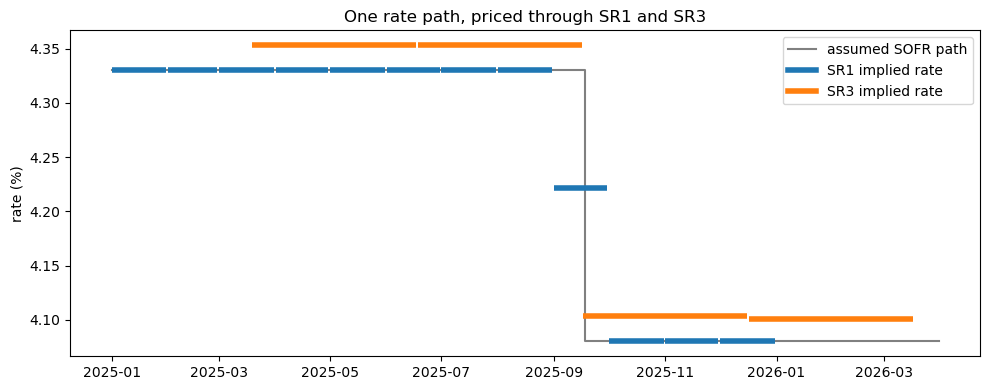

In [10]:
# Picture: each contract's implied rate over its own reference period,
# drawn on top of the daily SOFR path (a step function).
plt.figure(figsize=(10, 4))

shown = strip_path["2025-01-01":"2026-03-31"]
plt.step(shown.index, shown.values, where="post", color="gray", label="assumed SOFR path")

for _, row in contracts.iterrows():
    color = "tab:blue" if row["root"] == "SR1" else "tab:orange"
    plt.hlines(row["implied_rate"], row["reference_start"], row["reference_end"],
               colors=color, linewidth=4)

# Empty lines, only so the legend explains the colors.
plt.plot([], [], color="tab:blue", linewidth=4, label="SR1 implied rate")
plt.plot([], [], color="tab:orange", linewidth=4, label="SR3 implied rate")

plt.title("One rate path, priced through SR1 and SR3")
plt.ylabel("rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

**How to read this picture**

* **SR1** bars follow the gray path closely: one contract per month. September is the transition month:
  the cut starts on Sep 18, so 13 of its 30 days are at the lower rate, giving
  $(17 \times 4.33 + 13 \times 4.08)/30 = 4.2217\%$, which you can verify by hand.
* **SR3** bars sit a few basis points **above** the gray line. This is compounding (Section 4), not a market view.
* The SR3 quarter that ends on Sep 16 is untouched by a cut that starts on Sep 18. The next SR3 quarter
  starts on Sep 17, so almost all of its days are at the lower rate.

## 6. Why SR1 and SR3 carry different information

How much does a contract's price change if a 25 bp cut takes effect on a given day?
We try every business day from mid-August to the end of 2025 and look at two contracts:
SR1 September 2025 (a single month) and SR3 September 2025 (a full quarter).

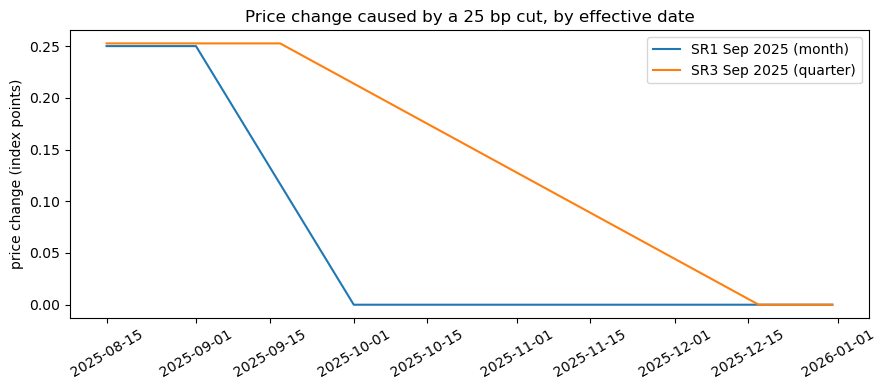

In [11]:
sr1_start, sr1_end = "2025-09-01", "2025-09-30"
sr3_start, sr3_end = "2025-09-17", "2025-12-16"

base_path = make_path("2025-08-01", "2026-01-31", 4.33)
base_sr1 = sr1_price(base_path, sr1_start, sr1_end)
base_sr3 = sr3_price(base_path, sr3_start, sr3_end)

effective_days = fixing_dates("2025-08-15", "2025-12-31")
sr1_change = []
sr3_change = []

for day in effective_days:
    cut_path = make_path("2025-08-01", "2026-01-31", 4.33, {day: -0.25})
    # A cut lowers the rate, so the price goes UP; we record the price change.
    sr1_change.append(sr1_price(cut_path, sr1_start, sr1_end) - base_sr1)
    sr3_change.append(sr3_price(cut_path, sr3_start, sr3_end) - base_sr3)

plt.figure(figsize=(9, 4))
plt.plot(effective_days, sr1_change, label="SR1 Sep 2025 (month)")
plt.plot(effective_days, sr3_change, label="SR3 Sep 2025 (quarter)")
plt.title("Price change caused by a 25 bp cut, by effective date")
plt.ylabel("price change (index points)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [12]:
# A few concrete numbers: the price change for a cut effective on these days.
example_days = ["2025-09-01", "2025-09-18", "2025-10-01", "2025-11-03"]
table = []
for day in example_days:
    cut_path = make_path("2025-08-01", "2026-01-31", 4.33, {day: -0.25})
    table.append({
        "cut effective": day,
        "SR1 Sep price change": sr1_price(cut_path, sr1_start, sr1_end) - base_sr1,
        "SR3 Sep price change": sr3_price(cut_path, sr3_start, sr3_end) - base_sr3,
    })
pd.DataFrame(table)

,cut effective,SR1 Sep price change,SR3 Sep price change
0,2025-09-01,0.2500,0.2526
1,2025-09-18,0.1083,0.2498
2,2025-10-01,0.0000,0.2138
3,2025-11-03,0.0000,0.1222


**Reading the chart**

* **SR1 September** reacts strongly to *when in September* a move happens. A cut effective Sep 18
  leaves 13 of 30 days, so the price moves by $0.25 \times 13/30 \approx 0.108$. A cut effective in October does nothing to it.
* **SR3 September** keeps reacting well into its quarter, so it captures the *cumulative* effect of moves over several months.
* When the cut is effective before the period starts, SR3 moves by slightly **more** than 0.25 (about 0.2526 here).
  Compounding makes the rate react a little more than one-for-one to a change in the rate level.

SR1 therefore helps separate nearby meetings, and SR3 constrains the longer-run path. This is the logic of
Section 6 in `docs/METHODOLOGY.md`.

## 7. Safety checks

The pricing functions refuse to price if the fixings do not cover the period.
This prevents a missing day from quietly reusing a stale rate.

In [13]:
def show_error(description, function, *arguments):
    # Run a pricing call and print the error message we expect to get.
    try:
        function(*arguments)
        print(f"{description}: no error (unexpected)")
    except (ValueError, TypeError) as error:
        print(f"{description}:\n    {type(error).__name__}: {error}\n")


# 1) Fixings start after the first day of the period.
late_start = make_path("2024-06-03", "2024-07-31", 5.0)
show_error("Fixings start too late", sr1_rate, late_start, "2024-06-01", "2024-06-30")

# 2) Fixings stop before the period ends.
early_stop = make_path("2024-05-01", "2024-06-14", 5.0)
show_error("Fixings stop too early", sr1_rate, early_stop, "2024-06-01", "2024-06-30")

# 3) Ten fixings are missing in the middle (this is data loss, not a weekend).
all_dates = fixing_dates("2024-05-01", "2024-07-31")
hole = pd.Series(5.0, index=all_dates.delete(range(20, 30)))
show_error("Fixings with a hole", sr1_rate, hole, "2024-06-01", "2024-06-30")

# 4) Unknown product.
ok_path = make_path("2024-05-01", "2025-04-30", 5.0)
show_error("Unknown product", contract_price, "ZN", ok_path, "2024-06-01", "2024-06-30")

Fixings start too late:
    ValueError: fixings start 2024-06-03, after the period start 2024-06-01; include the fixing on or before the start

Fixings stop too early:
    ValueError: fixings end 2024-06-14, too early to cover the period end 2024-06-30

Fixings with a hole:
    ValueError: gap between consecutive fixings is longer than a long weekend

Unknown product:
    ValueError: unknown product root 'ZN'; expected 'SR1' or 'SR3'



## 8. Unit tests

The tests compare our functions with numbers worked out by hand (the examples above) and with a second,
independent way of computing SR3. They also check that bad input is rejected.

In [14]:
result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests", "-v", "--tb=short", "--color=no", "-p", "no:cacheprovider"],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True,
)
print(result.stdout[-4500:])

============================= test session starts ==============================
platform darwin -- Python 3.13.5, pytest-8.3.4, pluggy-1.5.0 -- /opt/anaconda3/bin/python
rootdir: /Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project
plugins: anyio-4.7.0
collecting ... collected 23 items

tests/test_pricing.py::test_blocks_give_friday_three_days PASSED         [  4%]
tests/test_pricing.py::test_blocks_start_on_a_weekend_uses_friday_rate PASSED [  8%]
tests/test_pricing.py::test_fixing_dates_skips_weekends_and_holidays PASSED [ 13%]
tests/test_pricing.py::test_sr1_flat_path_gives_that_rate PASSED         [ 17%]
tests/test_pricing.py::test_sr1_price_is_100_minus_rate PASSED           [ 21%]
tests/test_pricing.py::test_sr1_midweek_cut PASSED                       [ 26%]
tests/test_pricing.py::test_sr1_monday_cut_keeps_old_rate_over_the_weekend PASSED [ 30%]
tests/test_pricing.py::test_sr1_month_that_starts_on_a_weekend PASSED    [ 34%]
tests/test_pricing.py::test_sr1_moves_b

## 9. Summary and what comes next

**Done in Issue #3**

* SR1 pricing: day-weighted average of SOFR over the calendar month.
* SR3 pricing: compounded SOFR over the IMM-to-IMM reference period, actual/360.
* Weekend and holiday rule: each fixing stays in force until the next fixing.
* `price_contracts`: one rate path in, one theoretical price per contract out.
* Safety checks for missing or inconsistent fixings, and unit tests with hand-checked values.

**Not done yet (known limits)**

* CME's final-settlement price rounding rule. Check the contract specification before adding it.
* The real SOFR holiday calendar. The default calendar is Monday to Friday; pass `holidays=[...]` to
  `fixing_dates` to match the SIFMA calendar.
* Speed. The code is written for clarity, and can be optimized when the solver needs it.

**Next, Issue #4**

* Build rate paths from FOMC meeting dates and rate moves.
* Search for the moves whose theoretical prices best match the observed market prices.